# Topic 9 - Machine Learning (Part 2)

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**What We Learnt in Topic 5 - Machine Learning (Part 1)**:

- Machine learning fundamentals
- Scikit-learn API
- Supervised/unsupervised learning
    * Classification, regression
    * Principal component analysis (PCA), clustering
- Model validation
    * Validation & learning curves
- Feature engineering
- Imputation of missing data

---

---

**Topic Learning Objectives**:

1. Understand machine learning algorithms - support vector machines (SVM), decision trees, random forests, kMeans, etc.
2. Apply machine learning techniques to real-world data
3. Evaluate machine learning solutions

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 9.0 Introduction </h2>
</div>

### 9.0.1 Bayes Theorem

#### *A Mental Puzzle*

*Steve is very shy and withdrawn, invariably helpful but with little interest in people or in the world of reality. A meek and tidy soul, he has a need for order and structure, and a passion for detail.*

In the context of the UK, is Steve more likely to be a **librarian** or a **farmer**?

---

Kahnemann & Tversky: Thinking Fast & Slow
- Irrational human judgements

Most respondents say that Steve is more likely to be librarian
- Based on a **stereotypical** view

But almost all people **ignore the prior probabilities**:
- The **ratio** of **farmers** to **librarians** in the population
- 167,000 to 19,300 in the UK in 2014 (8.65 to 1). Let's round up to 9 to 1

A rational judgement would consider both the **evidence** and the **prior probability**

---


Bayes Theorem (H=**hypothesis**, E=**evidence**): $$P(H|E) = \frac{P(H) P(E|H)}{P(E)}$$
Evidence should be used to **update** your beliefs, not **determine** them

Let's consider **prior probabiilities** and **evidence** for this puzzle
- We have total of 10 librarians and 90 farmers
- Let's assume 40% of librarians (4) and 10% of farmers (9) fit the description

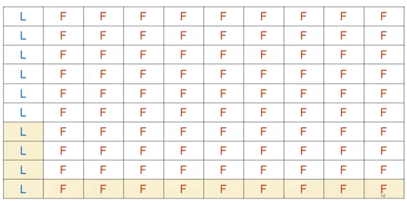

Hence, $P(Librarian|Description)$ = 4/(4+9) = 0.31 (Less than 0.5! The **evidence** doesn't outweigh the **priors**)

We can also apply Bayes Theorem formula:
* $P(Librarian)$ = 10/(10+90) = 0.1
* $P(Farmer)$ = 90/(10+90) = 0.9
* $P(Description|Librarian)$ = 0.4
* $P(Description|Farmer)$ = 0.1
* $P(Description)$ = (4+9)/(10+90) = 0.13

Hence, $P(Librarian|Description)$ = (0.1 * 0.4) / 0.13 = 0.31

---

#### *A Generalised Example*

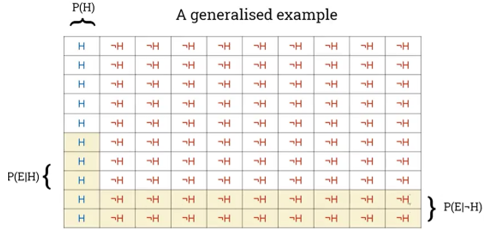

$P(Hypothesis|Evidence)$ = $P(H|E)$ = 5/(5+18) = 0.22

We can also apply Bayes Theorem formula:
* $P(H)$ = 10/(10+90) = 0.1
* $P( \neg H)$ = 90/(10+90) = 0.9
* $P(E|H)$ = 5/10 = 0.5
* $P(E| \neg H)$ = 18/90 = 0.2
* $P(E)$ = (5+18)/(10+90) = 0.23

Hence, $P(H|E) = \frac{P(H) P(E|H)}{P(E)}$ = (0.1 * 0.5) / 0.23 = 0.22

Bayes Theorem can be used whenever:
- Hypothesis
- Evidence
- Want to determine P(H|E)

Conceptualise in terms of areas rather than counts

---

**Summary:**
1. Bayes Theorem considers **evidence** in the context of **prior probabilities**
2. Evidence should be used to **update** your beliefs, not **determine** them
3. The likelihood of various **outcomes** can be represented **visually**

---

### 9.0.2 Naive Bayes Classification

Fast & simple classification algorithms
- High dimensional datasets
- Few tunable parameters: often used as a baseline

Recall our original Bayesian formula: 
$$P(H|E) = \frac{P(H) P(E|H)}{P(E)}$$

- P(H) is the 'Prior'
- P(E|H) is the 'Likelihood'
- P(H|E) is the 'Posterior'
- P(E) is the 'Marginal Likelihood' or 'Model Evidence'

For classification, we can think of this in terms of **features** and **labels**:

$$P(L|features) = \frac{P(L) P(features|L)}{P(features)}$$

To choose between labels, we can compare their **posterior probabilities**:

$$\frac{P(L_1 |features)}{P(L_2|features)} = \frac{P(L_1) P(features|L_1)}{P(L_2) P(features|L_2)}$$

Now we need to calculate $P(features|L_i)$ for each label

Assume a **generative** model for each label -> features. Specifying this model is the main part of training in Bayesian classifier

Why is it called Naive Bayes? Apply some simplifying ('naive') **assumptions**, e.g.
- Independence (all features are independent)
- Equality (all features contribute equally to the outcome)

Let's try an example using **Gaussian Naive Bayes**, which assumes data is drawn from a Gaussian distribution

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

In [ ]:
# let's generate some data
from sklearn.datasets import make_blobs
X, y = make_blobs(100, 2, centers=2, random_state=2, cluster_std=1.5)
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='RdBu');

In [ ]:
# assume data is generated by Gaussian,
# fit model by finding mean & std dev of points within each label
# now we can compute the Likelihood P(features|L) and from that the posterior
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X, y);

In [ ]:
# generate new data & predict label
rng = np.random.RandomState(0)
Xnew = [-6, -14] + [14, 18] * rng.rand(2000,2)
ynew = model.predict(Xnew)

In [ ]:
# plot to see decision boundary
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='RdBu')
lim = plt.axis()
plt.scatter(Xnew[:, 0], Xnew[:, 1], c=ynew, s=20, cmap='RdBu', alpha=0.1)
plt.axis(lim);
# notice how it is curved

In [ ]:
# can now compute posterior probabilities, showing uncertainty
# model assumptions can be limiting, by NB can still be useful esp. if #features is large
yprob = model.predict_proba(Xnew)
yprob.round(2)

---

**Summary:**
1. Naive Bayes classification assumes a **generative** model
2. We do classification by comparing **posterior probabilities** for each label
3. Naive Bayes relies on various **assumptions**

---

### 9.0.3 Multinomial Naive Bayes

Features are generated from a **multinomial distribution**
- Probability of observing **counts** across various **categories**
- Find a best-fit multinomial distribution

Example: text classification
- Categories are **word types**

Convert from **strings** to **numbers**
- Feature engineering: TfidfVectorizer()


In [ ]:
# download the 20 newsgroups corpus
from sklearn.datasets import fetch_20newsgroups
data = fetch_20newsgroups()
data.target_names

In [ ]:
# choose a subset of the categories
categories = ['rec.autos', 'misc.forsale',
              'talk.politics.misc', 'talk.politics.guns']
train = fetch_20newsgroups(subset='train', categories=categories)
test = fetch_20newsgroups(subset='test', categories=categories)

In [ ]:
# convert to a numerical vector
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

model = make_pipeline(TfidfVectorizer(), MultinomialNB())

In [ ]:
# apply model to the training data, then predict
model.fit(train.data, train.target)
labels = model.predict(test.data)

In [ ]:
# visualize the performance using a confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(test.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=train.target_names, yticklabels=train.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

# Note: Confusion matrix (mat) is a 2D array where:
# rows represent true classes, and 
# columns represent predicted classes

In [ ]:
# create a utility to categorise an arbitrary string
def predict_category(s, train=train, model=model):
    pred = model.predict([s])
    return train.target_names[pred[0]]

In [ ]:
predict_category('The conservative party voted in favour of Brexit')

In [ ]:
predict_category('The Uzi nine millimeter')

In [ ]:
predict_category('The mustang was a great vehicle')

In [ ]:
predict_category('Now is the winter of our discontent')  # from Shakespeare's "Richard III"

---

**Summary:**
1. Naive Bayes classification assumes a **generative** model
2. We use these generative models to **predict labels** for new points
3. Naive Bayes is a good **starting point** for **classification** tasks

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 9.1 In-Depth: Linear Regression </h2>
</div>

### 9.1.1 Simple Linear Regression

A good **starting point** for **regression** tasks:
- Can be fit very **quickly**
- Very **interpretable**

Commonly used to fit a **straight line** to 2D data, e.g., y = ax + b
- Can be extended to accommodate more **complex patterns**

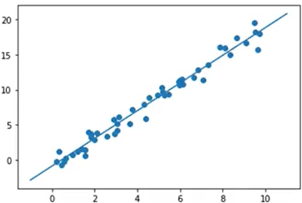


In [ ]:
# begin with the standard imports
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

In [ ]:
# start with a straight line fit
# create some data scattered about a line y = 2x - 5
rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = 2 * x - 5 + rng.rand(50)
plt.scatter(x, y);

In [ ]:
# use Scikit-Learn's LinearRegression estimator to fit this data and construct the best-fit line
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)

model.fit(x[:, np.newaxis], y)

xfit = np.linspace(0, 10, 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit);

In [ ]:
# inspect the key parameters
print("Model slope:    ", model.coef_[0])
print("Model intercept:", model.intercept_)

In [ ]:
# linear regression (LR) is much more capable than this
# consider multidimensional linear models equivalent to a hyperplane, 
# e.g., y = a0 + a1*x1 + a2*x2,... an*xn

In [ ]:
# tricky to visualize in 2D so we build some example data using Numpy's matrix multiplication
rng = np.random.RandomState(1)
X = 10 * rng.rand(100, 3)
y = 1.5 + np.dot(X, [2.5, -3, 0.5])

model.fit(X, y)
print(model.intercept_)
print(model.coef_)

In [ ]:
# can use LR to fit lines, planes, and hyperplanes to our data
# not limited to strictly linear relationships

---

**Summary:**
1. Simple linear regression is a good **starting point** for **regression** tasks
2. It can be **fitted quickly** and is highly **interpretable**
3. Can be extended to accommodate **multidimensional** data

---

### 9.1.2 Basis Function Regression

Can we use linear regression to model **nonlinear relationships**?
- Transform the data using basis functions
- Example: Polynomial features

Starting from a multidimensional **linear** model, e.g.

$$y = a_0 + a_1 x_1 + a_2 x_2 + \dots + a_n x_n$$

Then let:

$$x_n = f_n(\mathbf{x})$$

Where f(x) is some function that **transforms** our data, e.g.,

$$
f_n(\mathbf{x}) = x^n
$$

$$
y = a_0 + a_1 x + a_2 x^2 + \dots + a_n x^n
$$

Still a **linear** model!
- Coefficients are linearly independent and uncorrelated
- Projected one-dimensional x values into **higher dimensions**
- Linear fit can accommodate more **complex relationships**

**Polynomial** basis functions: PolynomialFeatures()

**Gaussian** basis functions: GaussianFeatures()

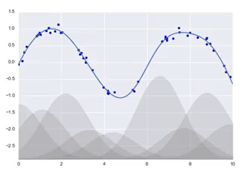 

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.06-linear-regression.html

#### *1. Polynomial Basis Functions*

In [ ]:
# begin with the standard imports
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

In [ ]:
# example: convert a 1D array into 3D array using the exponent of each value
from sklearn.preprocessing import PolynomialFeatures
x = np.array([2, 3, 4])
poly = PolynomialFeatures(3, include_bias=False)  # exclude intercept (no column of 1s)
poly.fit_transform(x[:, None])

In [ ]:
# create a pipeline for our transformer and linear regression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
poly_model = make_pipeline(PolynomialFeatures(7), 
                           LinearRegression())

In [ ]:
# create a sine wave with some noise
rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = np.sin(x) + 0.1 * rng.randn(50)

poly_model.fit(x[:, np.newaxis], y)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit);

In [ ]:
# Observation: 7th order polynomial is a good fit

#### *2. Gaussian Basis Functions*

- Other basis functions are possible: model = sum of Gaussian bases
- Not built into scikit-learn: can create own class (as shown in Coursera video)

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input"""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        # create N centers spread along the data range
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self
        
    def transform(self, X):
        return self._gauss_basis(X[:, :, np.newaxis], self.centers_,
                                 self.width_, axis=1)

gauss_model = make_pipeline(GaussianFeatures(20),
                            LinearRegression())
gauss_model.fit(x[:, np.newaxis], y)
yfit = gauss_model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit)
plt.xlim(0, 10);

---

**Summary:**
1. We can use linear regression to model **nonlinear relationships**
2. Transform the data using **basis functions**
3. Examples: **Polynomial** or **Gaussian**

---

### 9.1.3 Regularization

Introduction of basis functions makes model more **flexible**
- But can lead to **overfitting**
- Example of 30 polynomial features:

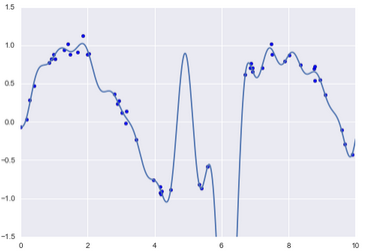

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.06-linear-regression.html


Plot the **coefficients** of the Gaussian bases against their **locations**
- Amplitude **oscillates** where basis functions overlap

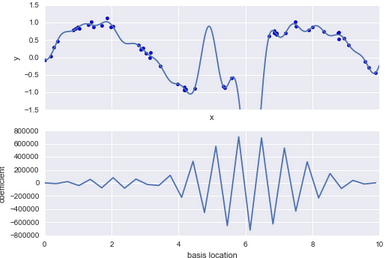

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.06-linear-regression.html


We need to **limit** such **spikes**
- **Penalize large values** of the model parameters

**Ridge regression**
- $L_2$ regularization
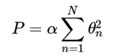

**Lasso regression**
- $L_1$ regularization
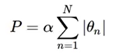


In [ ]:
# begin with the standard imports
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

In [ ]:
# create a sine wave with some noise
rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = np.sin(x) + 0.1 * rng.randn(50)

In [ ]:
# use Scikit-Learn's LinearRegression estimator to fit this data and construct the best-fit line
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)

model.fit(x[:, np.newaxis], y)

xfit = np.linspace(0, 10, 1000)
yfit = model.predict(xfit[:, np.newaxis])

In [ ]:
# create a custom transformer
from sklearn.base import BaseEstimator, TransformerMixin

class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input"""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        # create N centers spread along the data range
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self
        
    def transform(self, X):
        return self._gauss_basis(X[:, :, np.newaxis], self.centers_,
                                 self.width_, axis=1)

gauss_model = make_pipeline(GaussianFeatures(20),
                            LinearRegression())
gauss_model.fit(x[:, np.newaxis], y)
yfit = gauss_model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit)
plt.xlim(0, 10);

In [ ]:
# create a pipeline
model = make_pipeline(GaussianFeatures(30),
                      LinearRegression())
model.fit(x[:, np.newaxis], y)

plt.scatter(x, y)
plt.plot(xfit, model.predict(xfit[:, np.newaxis]))

plt.xlim(0, 10)
plt.ylim(-1.5, 1.5);

In [ ]:
# plot the basis function amplitudes
def basis_plot(model, title=None):
    fig, ax = plt.subplots(2, sharex=True)
    model.fit(x[:, np.newaxis], y)
    ax[0].scatter(x, y)
    ax[0].plot(xfit, model.predict(xfit[:, np.newaxis]))
    ax[0].set(xlabel='x', ylabel='y', ylim=(-1.5, 1.5))

    if title:
        ax[0].set_title(title)

    ax[1].plot(model.steps[0][1].centers_,
               model.steps[1][1].coef_)
    ax[1].set(xlabel='basis_location',
              ylabel='coefficient',
              xlim=(0, 10))

model = make_pipeline(GaussianFeatures(30),
                      LinearRegression())
basis_plot(model)

In [ ]:
# add ridge regression to our pipeline
# experiment with different values of alpha (e.g., 0.1, 0.01)
from sklearn.linear_model import Ridge
model = make_pipeline(GaussianFeatures(30), Ridge(alpha=0.01))  # try different alpha values
basis_plot(model, title='Ridge Regression')

In [ ]:
# add lasso regression to our pipeline
# experiment with different values of alpha (e.g., 0.01, 0.1)
from sklearn.linear_model import Lasso
model = make_pipeline(GaussianFeatures(30), Lasso(alpha=0.01))  # try different alpha values
basis_plot(model, title='Lasso Regression')

In [ ]:
# determine a value for alpha in a systematic manner, e.g., via cross validation

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 9.2 Support Vector Machines (SVMs) </h2>
</div>

---

**Recap: What We've Learnt So Far...**
1. **Naive Bayes classification** assumes a **generative** model for each class
2. We use these generative models to **predict labels** for new points
3. Naive Bayes relies on various **assumptions**

---

### 9.2.1 Introduction to SVMs

A type of **discriminative** classifier:
- Rather than **modeling** each class, we find a line to **separate the classes**
- Can be used for **classification** and **regression**

Consider a linearly separable pair of classes:

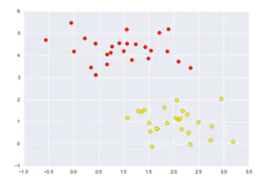
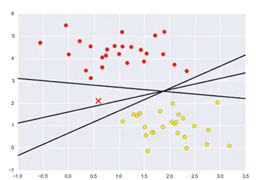 

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html

Maximising the margin
- Rather than simply drawing a **line**, think in terms of **maximizing** the **margin** between the classes
- Some separation lines have a wider margin than others:

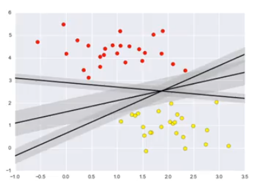

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html


In [ ]:
# create some sample data -- code extracted from VanderPlas (2016)
# https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.07-Support-Vector-Machines.ipynb
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

In [ ]:
# create a SVM
from sklearn.svm import SVC  # "support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

In [ ]:
# utility function to visualise the margin
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T    
    P = model.decision_function(xy).reshape(X.shape)

    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vector
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolor='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

In [ ]:
# now invoke it on our data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model);

In [ ]:
# show support vectors
model.support_vectors_

In [ ]:
# note that only the position of the support vectors (SVs) matter
# other points do not contribute to the loss function

def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.pca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
    

In [ ]:
# insensitivity to distant points is a strength of SVM

---

**Summary:**
1. SVMs are a type of **discriminative** classifier
2. It attempts to **maximize the margin** between classes
3. The points touching the margin are known as **support vectors**

---

### 9.2.2 Kernel SVMs

SVMs become more powerful when combined with **kernels**:
- Project data into a **higher dimensional space**

Consider a **non-linearly separable** pair of classes:

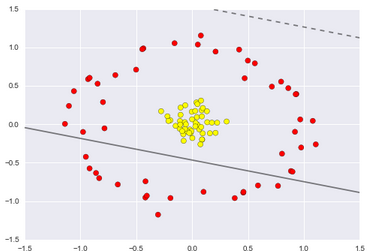

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html

No linear discrimination can separate the classes, but:
- Recall basis function regression: polynomial + Gaussian basis functions to model **non-linear** relationships with **linear** classifier

Could we project this data into a higher dimension? Example: a **radial basis** function

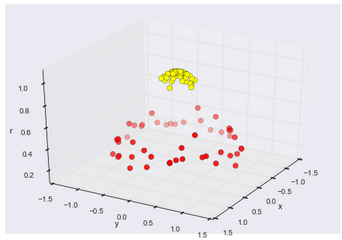

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html

How do we choose the **right projection**?
- Compute a basis function at **every point**, let SVM sift through results? **Computationally intensive** (N points * N dimensions)
- **Kernel trick**: allows us to **fit** on **transformed data** without computing coordinates in higher dimension space

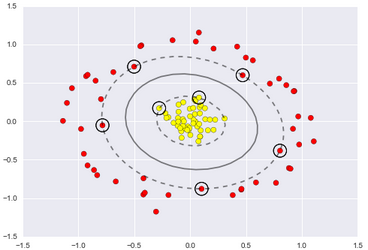

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.07-support-vector-machines.html


In [ ]:
# standard imports
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC  # "support vector classifier"

In [ ]:
# utility function to visualise the margin
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T    
    P = model.decision_function(xy).reshape(X.shape)

    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vector
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolor='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

In [ ]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [ ]:
# compute a radial basis function (RBF) centred on middle
r = np.exp(-(X**2).sum(1))

In [ ]:
# If next cell results in errors, uncomment code and run this cell
# Then open the notebook again and run the code

# !pip install ipywidgets==7.7.2
# !jupyter nbextension enable --py widgetsnbextension --sys-prefix
# !jupyter nbextension install --py widgetsnbextension --sys-prefix
# !jupyter notebook

In [ ]:
from ipywidgets import interact, fixed
from mpl_toolkits import mplot3d

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:,0], X[:,1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, 
         elev=(-90,90), 
         azim=(-180,180),
         X=fixed(X), 
         y=fixed(y));

In [ ]:
# you can also use this to plot -- code extracted from VanderPlas (2016)
# https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.07-Support-Vector-Machines.ipynb
from mpl_toolkits import mplot3d

ax = plt.subplot(projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
ax.view_init(elev=20, azim=30)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('r');

In [ ]:
# apply kernelized SVM by changing linear kernel to an RBF kernel
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

In [ ]:
# now shows the margins as we did before in the linear example
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:,0], clf.support_vectors_[:,1],
            s=300, lw=1, facecolors='none');
# Using a kernelized support vector machine, we learn a nonlinear decision boundary

In [ ]:
# what happens with data sets without a perfect decision boundary?
# consider a data set where the classes overlap
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn');

In [ ]:
# a 'hard' margin won't work on this data
# we need some way to accommodate errors, we do this by softening the margin
# we soften the margin using the C parameter: low C = soft margin (= more regularization)
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16,6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X,y)
    axi.scatter(X[:,0], X[:,1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:,0],
                model.support_vectors_[:,1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

In [ ]:
# find the optimal value for C systematically, e.g., via cross-validation

---

**Summary:**
1. Naive Bayes is an example of a simple **generative** classifier
2. SVMs are an example of a **discriminative** classifier
3. Both methods have strengths and weaknesses

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> References & Notes </h2>
</div>

**References**

- VanderPlas, J. (2016). *Python data science handbook: Essential tools for working with data*. O’Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/

**Notes**

-   Excerpts from Python Data Science Handbook by Jake VanderPlas are used. The text is released under the CC-BY-NC-ND license, and the code examples are released under the MIT license.